In [1]:
import pandas as pd

ab_events = pd.read_csv("../data/ab_events_clean.csv")

ab_events

,user_id,group,signup_date,grade,timestamp,event_type
0,U300000,B,2026-03-09,5,2026-05-04 19:36:00,login
1,U300000,B,2026-03-09,5,2026-05-07 19:35:00,login
2,U300000,B,2026-03-09,5,2026-05-07 19:42:00,homework_started
3,U300000,B,2026-03-09,5,2026-05-08 17:05:00,login
4,U300000,B,2026-03-09,5,2026-05-08 17:11:00,homework_started
...,...,...,...,...,...,...
179106,U305999,A,2025-06-19,11,2026-05-20 19:56:00,homework_started
179107,U305999,A,2025-06-19,11,2026-05-20 20:16:00,homework_completed
179108,U305999,A,2025-06-19,11,2026-05-21 20:47:00,login
179109,U305999,A,2025-06-19,11,2026-05-21 20:53:00,homework_started


In [2]:
ab_events[ab_events['event_type']=='login'].groupby('group')['user_id'].nunique()

group
A    2997
B    2995
Name: user_id, dtype: int64

In [3]:
ab_events[ab_events['event_type']=='homework_started'].groupby('group')['user_id'].nunique()

group
A    2997
B    2995
Name: user_id, dtype: int64

In [4]:
ab_events[ab_events['event_type']=='homework_completed'].groupby('group')['user_id'].nunique()

group
A    2926
B    2960
Name: user_id, dtype: int64

Конверсия в завершение: 

In [5]:
started = ab_events[
    ab_events['event_type'] == 'homework_started'
].groupby('group')['user_id'].nunique()

completed = ab_events[
    ab_events['event_type'] == 'homework_completed'
].groupby('group')['user_id'].nunique()

conversion = completed / started * 100
conversion.round(4)

group
A    97.6310
B    98.8314
Name: user_id, dtype: float64

In [6]:
diff_cr = conversion['B'] - conversion['A']
round(diff_cr, 4)

np.float64(1.2004)

Разница составляет примерно +1,20 процентного пункта в пользу B.

In [7]:
return_visit_d7 = ab_events[ab_events['event_type']=='return_visit_d7'].groupby('group')['user_id'].nunique()

return_visit_d7

group
A    2179
B    2335
Name: user_id, dtype: int64

In [8]:
return_visit_d14 = ab_events[ab_events['event_type']=='return_visit_d14'].groupby('group')['user_id'].nunique()

return_visit_d14

group
A     862
B    1085
Name: user_id, dtype: int64

In [9]:
total_users = ab_events.groupby('group')['user_id'].nunique()

retention_d7 = return_visit_d7/total_users*100
retention_d14 = return_visit_d14/total_users*100

retention_d7

group
A    72.706039
B    77.963272
Name: user_id, dtype: float64

In [10]:
retention_d14

group
A    28.762095
B    36.227045
Name: user_id, dtype: float64

In [11]:
retention_d7['B'] - retention_d7['A']

np.float64(5.257232747494285)

In [12]:
retention_d14['B'] - retention_d14['A']

np.float64(7.464949646363113)

В группе B наблюдается более высокое удержание на обоих горизонтах.

Интересно, что преимущество B группы на 14 день больше, чем на 7 день. Это потенциально хороший сигнал: изменение может быть связано не только с краткосрочной активностью, но и с более длительным возвращением пользователей.

Однако пока нельзя утверждать, что изменение вызвало улучшение.

In [13]:
homework_started = ab_events[ab_events['event_type']=='homework_started'].groupby('group')['user_id'].count()

homework_started

group
A    32245
B    35982
Name: user_id, dtype: int64

In [14]:
homework_completed = ab_events[ab_events['event_type']=='homework_completed'].groupby('group')['user_id'].count()

homework_completed

group
A    11895
B    17068
Name: user_id, dtype: int64

In [15]:
homework_completion_ratio = homework_completed / homework_started * 100
round(homework_completion_ratio, 4)

group
A    36.8894
B    47.4348
Name: user_id, dtype: float64

In [16]:
diff_homework = (
    homework_completion_ratio['B']
    - homework_completion_ratio['A']
)

round(diff_homework, 2)

np.float64(10.55)

Разница B − A: +10,55 процентного пункта.

In [17]:
metrics_summary = pd.DataFrame({
    'conversion': conversion,
    'retention_d7': retention_d7,
    'retention_d14': retention_d14,
    'homework_completion_ratio': homework_completion_ratio
    })
metrics_summary.loc['B - A'] = (metrics_summary.loc['B'] - metrics_summary.loc['A'])

metrics_summary.round(2)

,conversion,retention_d7,retention_d14,homework_completion_ratio
group,,,,
A,97.63,72.71,28.76,36.89
B,98.83,77.96,36.23,47.43
B - A,1.20,5.26,7.46,10.55


<Axes: title={'center': 'Факт возврата на 7 день и на 14: A vs B'}, xlabel='Группа', ylabel='Значение, %'>

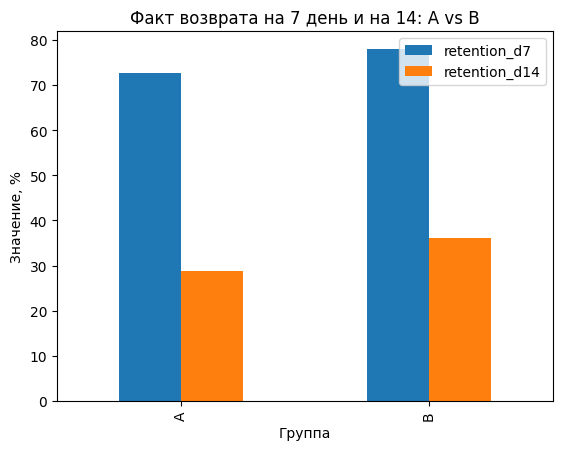

In [18]:
metrics_summary.loc[
    ['A', 'B'],
    ['retention_d7', 'retention_d14']
].plot(kind='bar',
       title='Факт возврата на 7 день и на 14: A vs B',
       xlabel='Группа',
       ylabel='Значение, %')

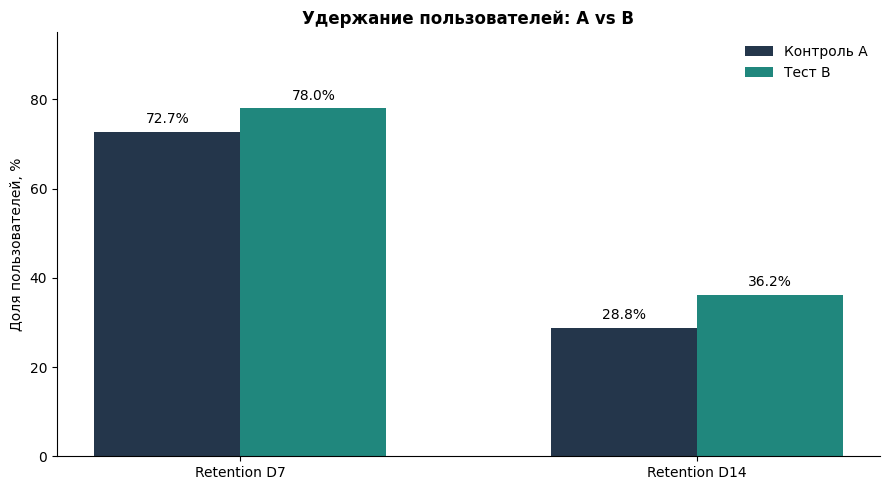

In [22]:

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

Path("../images").mkdir(exist_ok=True)

metrics = ["Retention D7", "Retention D14"]
a = metrics_summary.loc["A", ["retention_d7", "retention_d14"]].values
b = metrics_summary.loc["B", ["retention_d7", "retention_d14"]].values

x = np.arange(len(metrics))
width = 0.32

fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor("white")

bars_a = ax.bar(x - width/2, a, width, label="Контроль A", color="#24364B")
bars_b = ax.bar(x + width/2, b, width, label="Тест B", color="#20877D")

ax.bar_label(bars_a, fmt="%.1f%%", padding=4)
ax.bar_label(bars_b, fmt="%.1f%%", padding=4)

ax.set_xticks(x, metrics)
ax.set_ylim(0, 95)
ax.set_ylabel("Доля пользователей, %")
ax.set_title("Удержание пользователей: A vs B", fontweight="bold")
ax.legend(frameon=False)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

plt.savefig("../images/retention_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


## Conversion Funnel - Login → Homework Started → Homework Completed

Воронка отражает долю уникальных пользователей, совершивших
соответствующие события в течение эксперимента.

Событие `homework_completed` означает завершение хотя бы одного
домашнего задания, а не полное прохождение курса.

В отсутствие идентификатора задания и события завершения курса
рассчитать истинный Course Completion Rate невозможно.

In [19]:
funnel_events = [
    'login',
    'homework_started',
    'homework_completed'
]

funnel = (
    ab_events[
        ab_events['event_type'].isin(funnel_events)
    ]
    .groupby(['event_type', 'group'])['user_id']
    .nunique()
    .unstack('group')
    .reindex(funnel_events)
)

funnel

group,A,B
event_type,,
login,2997,2995
homework_started,2997,2995
homework_completed,2926,2960


<Axes: title={'center': 'Conversion Funnel: A vs B'}, xlabel='Unique Users', ylabel='Funnel Stage'>

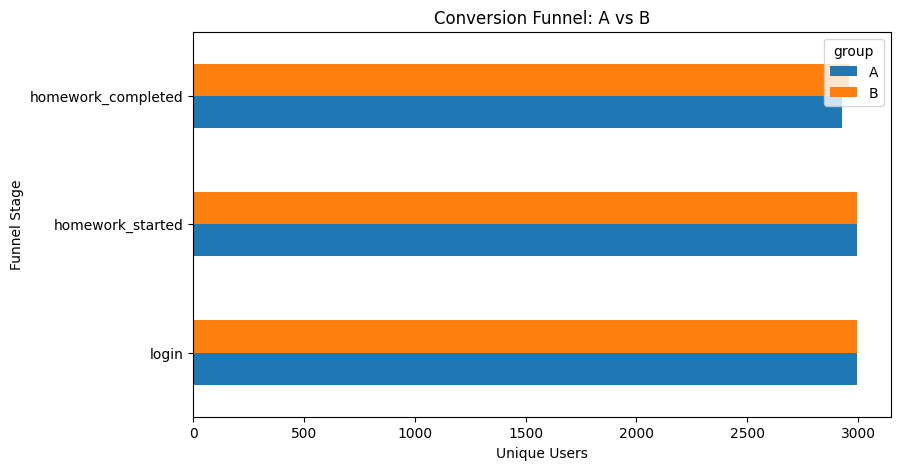

In [20]:
funnel.plot(
    kind='barh',
    title='Conversion Funnel: A vs B',
    xlabel='Unique Users',
    ylabel='Funnel Stage',
    figsize=(9, 5)
)

In [21]:
funnel_conversion = (
    funnel.div(funnel.loc['login']) * 100
)

funnel_conversion.round(2)

group,A,B
event_type,,
login,100.00,100.00
homework_started,100.00,100.00
homework_completed,97.63,98.83


### Funnel Analysis - вывод

В обеих экспериментальных группах 100% пользователей совершили вход на платформу и начали хотя бы одно домашнее задание.

Доля пользователей, завершивших хотя бы одно домашнее задание, составила 97,63% в контрольной группе A и 98,83% в тестовой группе B.

Разница составляет **+1,20 процентного пункта** в пользу группы B.

Воронка рассчитана по уникальным пользователям, имеющим соответствующие события, без проверки их хронологической последовательности. Полное завершение курса напрямую не измеряется из-за отсутствия соответствующего события в данных.